# Module 05 — Gradient Norms and Gradient Clipping

This notebook measures global gradient norms, applies proportional clipping, and compares training with and without clipping.

## 1. Global norm and proportional clipping

In [1]:
import matplotlib.pyplot as plt
import torch
import torch.nn as nn


def global_norm(tensors):
    norms = [
        tensor.detach().float().norm(2)
        for tensor in tensors
        if tensor is not None
    ]
    if not norms:
        return 0.0
    return torch.linalg.vector_norm(torch.stack(norms), ord=2).item()


def clip_vector(gradient, max_norm):
    norm = gradient.norm()
    scale = min(1.0, max_norm / (norm.item() + 1e-12))
    clipped = gradient * scale
    return norm.item(), scale, clipped, clipped.norm().item()


gradient = torch.tensor([3.0, 4.0, 12.0])
print("Global norm:", global_norm([gradient]))

for threshold in (20.0, 5.0, 1.0):
    before, scale, clipped, after = clip_vector(gradient, threshold)
    print(
        f"threshold={threshold:>4.1f} | before={before:>5.2f} | "
        f"scale={scale:>6.3f} | after={after:>5.2f} | "
        f"vector={clipped.tolist()}"
    )

Global norm: 13.0
threshold=20.0 | before=13.00 | scale= 1.000 | after=13.00 | vector=[3.0, 4.0, 12.0]
threshold= 5.0 | before=13.00 | scale= 0.385 | after= 5.00 | vector=[1.1538461446762085, 1.5384615659713745, 4.615384578704834]
threshold= 1.0 | before=13.00 | scale= 0.077 | after= 1.00 | vector=[0.23076924681663513, 0.3076923191547394, 0.9230769872665405]


## 2. PyTorch clipping order

The norm is measured after `backward()` and before `optimizer.step()`.

In [2]:
model = nn.Linear(4, 1)
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)
x = torch.randn(8, 4)
y = torch.randn(8, 1)

optimizer.zero_grad(set_to_none=True)
prediction = model(x)
loss = nn.functional.mse_loss(prediction, y)
loss.backward()

grad_norm_before = torch.nn.utils.clip_grad_norm_(
    model.parameters(),
    max_norm=1.0,
)
grad_norm_after = global_norm(
    parameter.grad for parameter in model.parameters()
)
optimizer.step()

print("Loss:", loss.item())
print("Norm before clipping:", grad_norm_before.item())
print("Norm after clipping:", grad_norm_after)

Loss: 2.0506486892700195
Norm before clipping: 2.729764938354492
Norm after clipping: 0.9999997019767761


## 3. Monitor clipping frequency

Steps clipped: 7 / 12
Clipping frequency: 58.3%


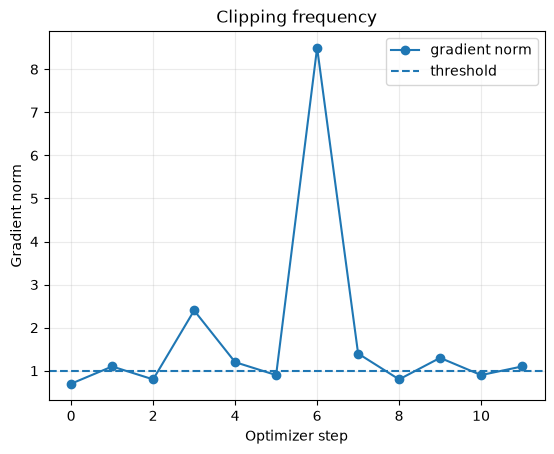

In [3]:
gradient_norms = [0.7, 1.1, 0.8, 2.4, 1.2, 0.9, 8.5, 1.4, 0.8, 1.3, 0.9, 1.1]
threshold = 1.0
clipped_steps = sum(norm > threshold for norm in gradient_norms)
frequency = clipped_steps / len(gradient_norms)

print("Steps clipped:", clipped_steps, "/", len(gradient_norms))
print("Clipping frequency:", f"{frequency:.1%}")

plt.plot(gradient_norms, marker="o", label="gradient norm")
plt.axhline(threshold, linestyle="--", label="threshold")
plt.xlabel("Optimizer step")
plt.ylabel("Gradient norm")
plt.title("Clipping frequency")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 4. Train with and without clipping

Occasionally large inputs create gradient spikes in an otherwise simple regression task.

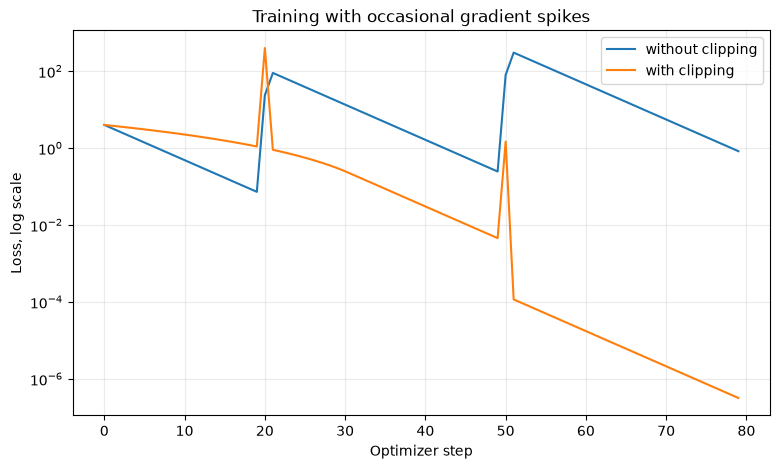

Step 20, unclipped gradient: 194.522705078125
Step 20, clipped gradient: 1.0
Weight after clipped update: 1.049999713897705


In [4]:
def train_with_spikes(clip=False, steps=80):
    torch.manual_seed(42)
    weight = torch.nn.Parameter(torch.tensor(0.0))
    optimizer = torch.optim.SGD([weight], lr=0.05)

    x_values = torch.ones(steps)
    x_values[20] = 20.0
    x_values[50] = 20.0

    history = {
        "loss": [],
        "grad_before": [],
        "grad_after": [],
        "weight": [],
    }

    for step in range(steps):
        optimizer.zero_grad(set_to_none=True)
        x = x_values[step]
        y = 2.0 * x
        loss = (weight * x - y) ** 2
        loss.backward()

        before = abs(weight.grad.item())
        if clip:
            torch.nn.utils.clip_grad_norm_([weight], max_norm=1.0)
        after = abs(weight.grad.item())
        optimizer.step()

        history["loss"].append(loss.item())
        history["grad_before"].append(before)
        history["grad_after"].append(after)
        history["weight"].append(weight.item())

    return history


unclipped = train_with_spikes(clip=False)
clipped = train_with_spikes(clip=True)

plt.figure(figsize=(9, 5))
plt.plot(unclipped["loss"], label="without clipping")
plt.plot(clipped["loss"], label="with clipping")
plt.yscale("log")
plt.xlabel("Optimizer step")
plt.ylabel("Loss, log scale")
plt.title("Training with occasional gradient spikes")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

print("Step 20, unclipped gradient:", unclipped["grad_before"][20])
print("Step 20, clipped gradient:", clipped["grad_after"][20])
print("Weight after clipped update:", clipped["weight"][20])

## Exercises

1. Change `max_norm` and observe when clipping becomes active.
2. Add gradient accumulation and clip only after all microbatches.
3. Add `error_if_nonfinite=True` to the clipping call.
4. If CUDA and FP16 are available, test the unscale-before-clip ordering with `GradScaler`.